# 01 · EDA de los recursos del centro

**Bloque del objetivo.** `01_EDA_recursos_alumno` mide los recursos de estudio del hogar del alumno. Este notebook hace lo mismo con los recursos de su centro, para decidir si entran en el modelo y cómo: como variable de interés, como control o no entran. Usa el panel de 12 países del análisis (los que tienen el índice de compromiso en las cuatro ediciones, `01_EDA_indice_de_compromiso_competencia`) y los alumnos cuyo centro tiene perfil (`00_Pipeline_generacion_estratos`).

Preguntas que responde:

* ¿Qué recursos del centro se pueden comparar entre 2012 y 2022? (sección 1)
* ¿En qué países y ediciones faltan? (sección 2)
* ¿Miden algo común, es decir, tiene sentido resumirlos en un índice? (secciones 3 y 4)
* ¿Cómo evolucionan, y dónde está su variación: entre países, ediciones, perfiles de centro, centros o alumnos? (secciones 5 y 6)
* ¿Cómo se relacionan con la composición social del centro, con las variables del alumno y con su nota? (secciones 7 y 8)
* ¿La escasez de 2012, medida con otras preguntas, se comporta como la de 2015-2022? (sección 9)
* ¿Los alumnos de centros sin dato son distintos? (sección 10)

Los recursos de cada centro salen del cuestionario de centro que responde el director, con nombres comunes a todas las ediciones (`leer_recursos_centros` de `src/pisa_pipeline.py`, guardados por `01_EDA_equidad` en `data/intermediate/recursos_anual/`). Los índices están en `src/recursos_centro.py`. Las correlaciones y regresiones con la nota se calculan con cada valor plausible de matemáticas por separado y se promedian (`estimar_con_pv`).

## 0. Configuración

In [1]:
import os
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

sys.path.append(os.path.abspath('../../'))   # para importar `src`
from src.pisa_estadisticas import agregar_media_ponderada, centrar_en_grupos, estimar_con_pv, regresion_dentro_de_grupos, reparto_varianza
from src.pisa_pipeline import VARIABLES_RECURSOS_CENTRO
from src.recursos_alumno import alfa_cronbach
from src.recursos_centro import (ESCASEZ_2012, GRUPO_PAIS_EDICION, VARIABLES_DOTACION, VARIABLES_ESCASEZ, cargas_primera_componente, construir_indices,
                                 estandarizar_conjunto, leer_centros, transformar_recursos)
from src.tabla_alumno import paises_panel, tabla_por_alumno

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.width', 200)

RUTA_RAW_BASE = '../../data/raw'
RUTA_INTERMEDIOS = '../../data/intermediate'
RUTA_REPORTS = '../../reports'
EDICIONES = [2012, 2015, 2018, 2022]
CANDIDATAS = ['alumnos_por_profesor', 'tamaño_clase', 'ordenadores_por_alumno', 'profesores_certificados_pct'] + VARIABLES_ESCASEZ
INDICES = ['dotacion_centro', 'dotacion_centro_equiponderado', 'escasez_centro']

# Panel común de 12 países: los que tienen el índice de compromiso en las cuatro ediciones
PANEL = paises_panel(RUTA_INTERMEDIOS)
print(f'{len(PANEL)} países:', ', '.join(PANEL))

# Centros del panel (una fila por centro y edición), con la escasez de 2012 de sus columnas equivalentes
centros = leer_centros(RUTA_RAW_BASE, RUTA_INTERMEDIOS, PANEL)

# Alumnos del panel con perfil de centro, sus valores plausibles, su origen social, sus recursos de estudio y su compromiso
# (sin los índices del centro que añade `tabla_por_alumno`: aquí se calculan y se unen en la sección 6)
alumnos = tabla_por_alumno(RUTA_RAW_BASE, RUTA_INTERMEDIOS).drop(columns=['dotacion_centro', 'escasez_centro'])
pd.DataFrame({'centros': centros.groupby('year').size(), 'alumnos con perfil': alumnos.groupby('year').size(),
              'centros con alumnos con perfil': alumnos.groupby('year')['centro'].nunique()}).T

12 países: AUS, DNK, ESP, GBR, GRC, HUN, ISL, ITA, KOR, POL, SVK, SVN


year,2012,2015,2018,2022
centros,5154,3856,4984,4536
alumnos con perfil,115762,78136,110023,105078
centros con alumnos con perfil,4775,3262,4428,4126


## 1. Qué recursos del centro se pueden comparar

El cuestionario de centro tiene más variables de las que describen la dotación del centro (`VARIABLES_RECURSOS_CENTRO` en `src/pisa_pipeline.py`). Algunas se descartan de entrada:

* **Tamaño del centro y titularidad**: definen el perfil del centro (`00_Pipeline_generacion_estratos`), así que no pueden ser a la vez variable que se compara dentro del perfil.
* **Financiación por origen** (gobierno, cuotas, donaciones): describe de dónde sale el dinero, ligado a la titularidad, no de cuántos recursos dispone el centro.
* **Autonomía sobre los recursos**: no existe en 2018 y no es comparable entre ediciones (`01_EDA_equidad`).
* **Profesorado con máster**: solo existe en 2022.

Quedan seis candidatas: alumnos por profesor, tamaño de clase, ordenadores por alumno, % de profesorado certificado y escasez de material y de personal según el director. La tabla muestra la columna original de cada edición y su etiqueta, y después su distribución por edición, para ver si cambian de escala.

In [2]:
diccionario = pd.read_csv(os.path.join(RUTA_INTERMEDIOS, 'diccionario_columnas.csv'), encoding='utf-8-sig')
colegios = diccionario[diccionario['TABLA'] == 'colegios']
filas = {}
for variable in CANDIDATAS:
    for edicion in EDICIONES:
        disponibles = colegios.loc[colegios['EDICION'] == edicion, 'COLUMNA']
        candidatas = (ESCASEZ_2012[variable][0],) if edicion == 2012 and variable in ESCASEZ_2012 else VARIABLES_RECURSOS_CENTRO[variable]
        columna = next((candidata for candidata in candidatas if candidata in set(disponibles)), None)
        etiqueta = colegios.loc[(colegios['EDICION'] == edicion) & (colegios['COLUMNA'] == columna), 'ETIQUETA']
        signo = ' (con el signo cambiado)' if edicion == 2012 and variable in ESCASEZ_2012 and ESCASEZ_2012[variable][1] < 0 else ''
        filas[(variable, edicion)] = f'{columna}: {etiqueta.iloc[0]}{signo}' if columna else '-'
with pd.option_context('display.max_colwidth', 80):
    display(pd.Series(filas).unstack())

print('Distribución por edición (centros del panel, sin ponderar):')
display(centros.groupby('year')[CANDIDATAS].describe(percentiles=[0.01, 0.5, 0.99])
        .T.loc[(slice(None), ['count', 'mean', '1%', '50%', '99%', 'max']), :].round(2))
print('% de centros con todo el profesorado certificado (100 %):',
      centros.dropna(subset=['profesores_certificados_pct']).groupby('year')['profesores_certificados_pct'].apply(lambda serie: round(100 * (serie >= 99.95).mean(), 1)).to_dict())
print('Valores distintos de tamaño de clase:', sorted(centros['tamaño_clase'].dropna().unique()))

,2012,2015,2018,2022
alumnos_por_profesor,STRATIO: Student-Teacher ratio,STRATIO: Student-Teacher ratio,STRATIO: Student-Teacher ratio,STRATIO: Student-teacher ratio
escasez_material_educativo,SCMATEDU: Quality of school educational resources (con el signo cambiado),EDUSHORT: Shortage of educational material (WLE),EDUSHORT: Shortage of educational material (WLE),EDUSHORT: Shortage of educational material (WLE)
escasez_personal,TCSHORT: Shortage of teaching Staff,STAFFSHORT: Shortage of educational staff (WLE),STAFFSHORT: Shortage of educational staff (WLE),STAFFSHORT: Shortage of educational staff (WLE)
ordenadores_por_alumno,RATCMP15: Ratio of computers for education and number of students in the <na...,RATCMP1: Number of available computers per student at modal grade,RATCMP1: Number of available computers per student at modal grade,RATCMP1: Availability of computers
profesores_certificados_pct,PROPCERT: Proportion of certified teachers,PROATCE: Index proportion of all teachers fully certified,PROATCE: Index proportion of all teachers fully certified,PROATCE: Proportion of all teachers fully certified
tamaño_clase,CLSIZE: Class size,CLSIZE: Class Size,CLSIZE: Class Size,CLSIZE: Class size (test language class)


Distribución por edición (centros del panel, sin ponderar):


year                                  2012     2015     2018     2022
alumnos_por_profesor        count  4640.00  3239.00  4357.00  3866.00
                            mean     11.55    11.76    11.29    11.12
                            1%        1.68     1.08     1.07     1.29
                            50%      11.50    11.91    11.23    11.14
                            99%      20.93    20.86    21.14    20.42
                            max     139.00   100.00   100.00   100.00
tamaño_clase                count  4857.00  3403.00  4598.00  4028.00
                            mean     24.49    23.86    24.08    23.86
                            1%       13.00    13.00    13.00    13.00
                            50%      23.00    23.00    23.00    23.00
                            99%      53.00    53.00    53.00    53.00
                            max      53.00    53.00    53.00    53.00
ordenadores_por_alumno      count  4784.00  3171.00  4263.00  3789.00
                            mean      0.85     0.97     0.91     0.91
                            1%        0.07     0.08     0.07     0.00
                            50%       0.67     0.79     0.81     0.93
                            99%       4.66     4.67     4.12     4.68
                            max      21.14    34.70    25.00    23.79
profesores_certificados_pct count  4160.00  2699.00  3630.00  3240.00
                            mean     93.60    91.69    88.38    84.56
                            1%        3.40     0.00     0.00     0.00
                            50%     100.00   100.00   100.00   100.00
                            99%     100.00   100.00   100.00   100.00
                            max     100.00   100.00   100.00   100.00
escasez_material_educativo  count  4935.00  3326.00  4618.00  4024.00
                            mean     -0.12    -0.03     0.04    -0.25
                            1%       -1.98    -1.25    -1.42    -1.42
                            50%      -0.02    -0.13     0.10    -0.26
                            99%       1.96     3.61     2.96     2.96
                            max       3.59     3.63     2.96     2.96
escasez_personal            count  4929.00  3322.00  4608.00  3562.00
                            mean     -0.19    -0.21    -0.07     0.04
                            1%       -1.09    -1.68    -1.46    -2.11
                            50%      -0.28    -0.10     0.03     0.18
                            99%       2.09     2.00     2.11     2.67
                            max       3.60     3.72     4.04     4.09

% de centros con todo el profesorado certificado (100 %): {2012: 67.2, 2015: 62.8, 2018: 65.2, 2022: 59.0}
Valores distintos de tamaño de clase: [np.float64(13.0), np.float64(18.0), np.float64(23.0), np.float64(28.0), np.float64(33.0), np.float64(38.0), np.float64(43.0), np.float64(48.0), np.float64(53.0)]


**Qué se ve.**

* **Alumnos por profesor y tamaño de clase son la misma pregunta en las cuatro ediciones.** El tamaño de clase viene en los mismos 9 tramos (de 13 a 53 alumnos, el punto medio de cada tramo), aunque en 2022 se refiere a la clase de lengua.
* **Ordenadores por alumno cambia de columna** (`RATCMP15` en 2012, `RATCMP1` después) y de etiqueta en 2022 («Availability of computers»). Su mediana sube de 0,67 en 2012 a 0,93 en 2022; con estos datos no se puede separar cuánto es cambio real y cuánto cambio de pregunta.
* **Hay valores extremos**: hasta 139 alumnos por profesor en 2012 (el percentil 99 está en torno a 21) y hasta 34,7 ordenadores por alumno (percentil 99 en torno a 4,7). Por eso se recortan los extremos antes de construir el índice.
* **El profesorado certificado tiene techo**: entre el 59,0 % y el 67,2 % de los centros tienen al 100 % del profesorado certificado, así que distingue poco entre centros.
* **La escasez de material y de personal (`EDUSHORT` y `STAFFSHORT`) solo existe desde 2015.** En 2012 se usan sus equivalentes del cuestionario de centro: la calidad de los recursos educativos (`SCMATEDU`), con el signo cambiado para que más sea más escasez, y la escasez de profesores (`TCSHORT`). Son otras preguntas, que solo cubren a los profesores de matemáticas, ciencias y lengua y no la infraestructura (sección 9).

## 2. Cobertura por país y edición

% de centros con cada variable en cada país y edición. Un 0 es una pregunta que el país no hizo o no publicó.

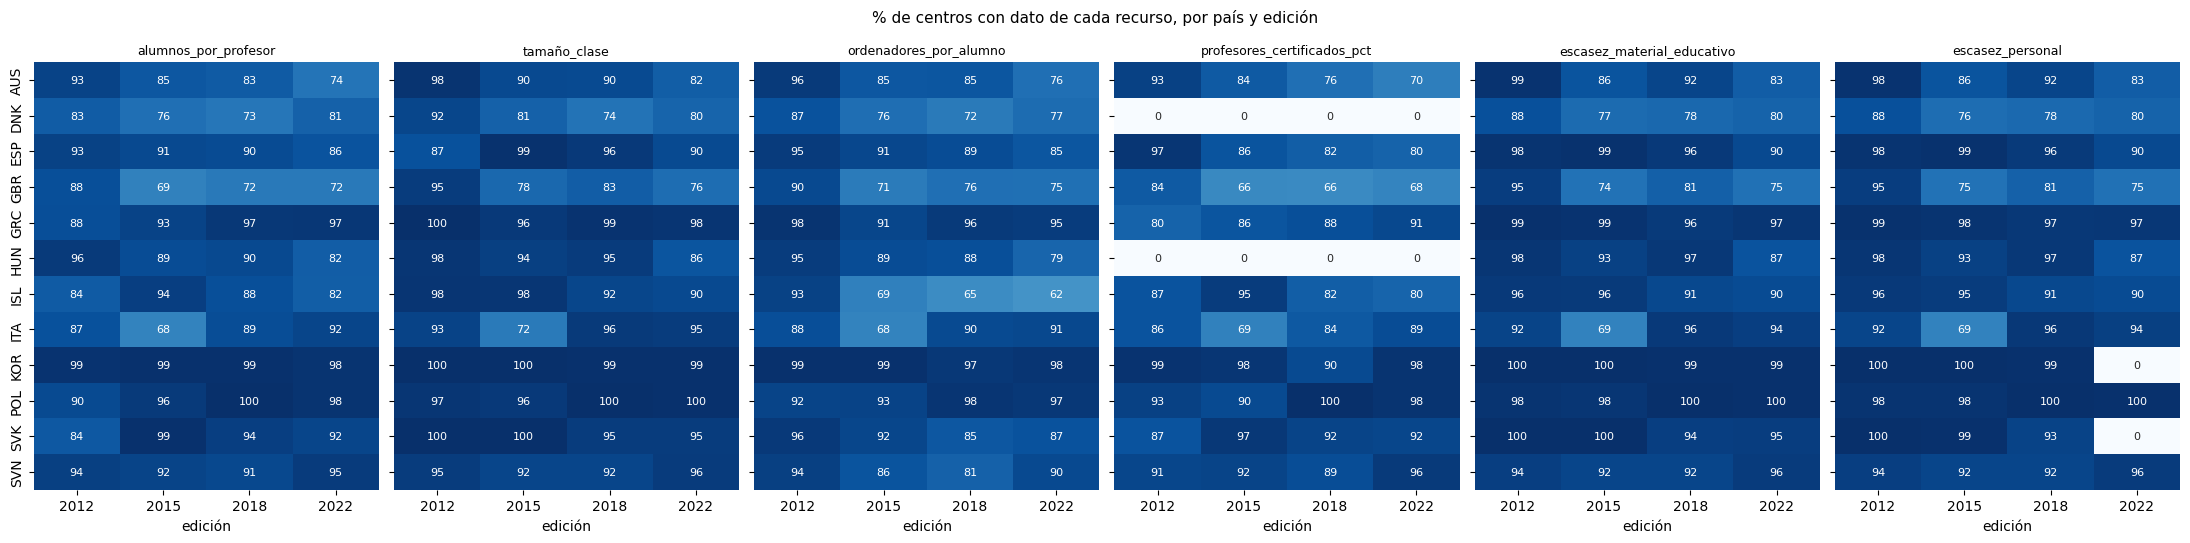

In [3]:
cobertura = centros.groupby(['CNT', 'year'])[CANDIDATAS].apply(lambda grupo: grupo.notna().mean().mul(100))
fig, ejes = plt.subplots(1, len(CANDIDATAS), figsize=(22, 5.5), sharey=True)
for eje, variable in zip(ejes, CANDIDATAS):
    sns.heatmap(cobertura[variable].unstack('year'), annot=True, fmt='.0f', cmap='Blues', vmin=0, vmax=100, cbar=False, ax=eje, annot_kws={'fontsize': 8})
    eje.set_title(variable, fontsize=9)
    eje.set_xlabel('edición')
    eje.set_ylabel('')
fig.suptitle('% de centros con dato de cada recurso, por país y edición', fontsize=11)
plt.tight_layout()
fig.savefig(f'{RUTA_REPORTS}/01_recursos_centro_cobertura.png', dpi=300, bbox_inches='tight')
plt.show()

**Qué se ve.**

* **Alumnos por profesor, tamaño de clase y ordenadores por alumno existen en los 12 países y las cuatro ediciones**, casi siempre para más del 80 % de los centros. Los huecos más grandes están en Reino Unido (69-72 % de centros con alumnos por profesor desde 2015), Italia en 2015 (68-72 %) e Islandia en ordenadores (62-69 % desde 2015).
* **El profesorado certificado falta entero en Dinamarca y Hungría** en las cuatro ediciones.
* **La escasez de personal falta entera en Corea y Eslovaquia en 2022**, así que el índice de escasez no existe para esos dos países en esa edición.

## 3. ¿Miden algo común?

Para resumir varias variables en un índice tienen que moverse juntas. Se mira dentro de cada país-edición (cada centro, comparado con los de su país y edición), que es la comparación que hará el modelo, y cada centro pesa igual. Dos versiones de la correlación:

* **por rangos** (Spearman: el puesto de cada centro dentro de su país-edición), que no depende de los valores extremos ni de la escala;
* **de Pearson tras transformar** las variables como se hará en el índice: recorte de los valores por debajo del percentil 1 y por encima del 99 (con todas las ediciones juntas) y logaritmo de las dos razones, alumnos por profesor y ordenadores por alumno, que tienen una cola larga (`transformar_recursos`).

Si las dos versiones se parecen, la transformación no deforma la relación.

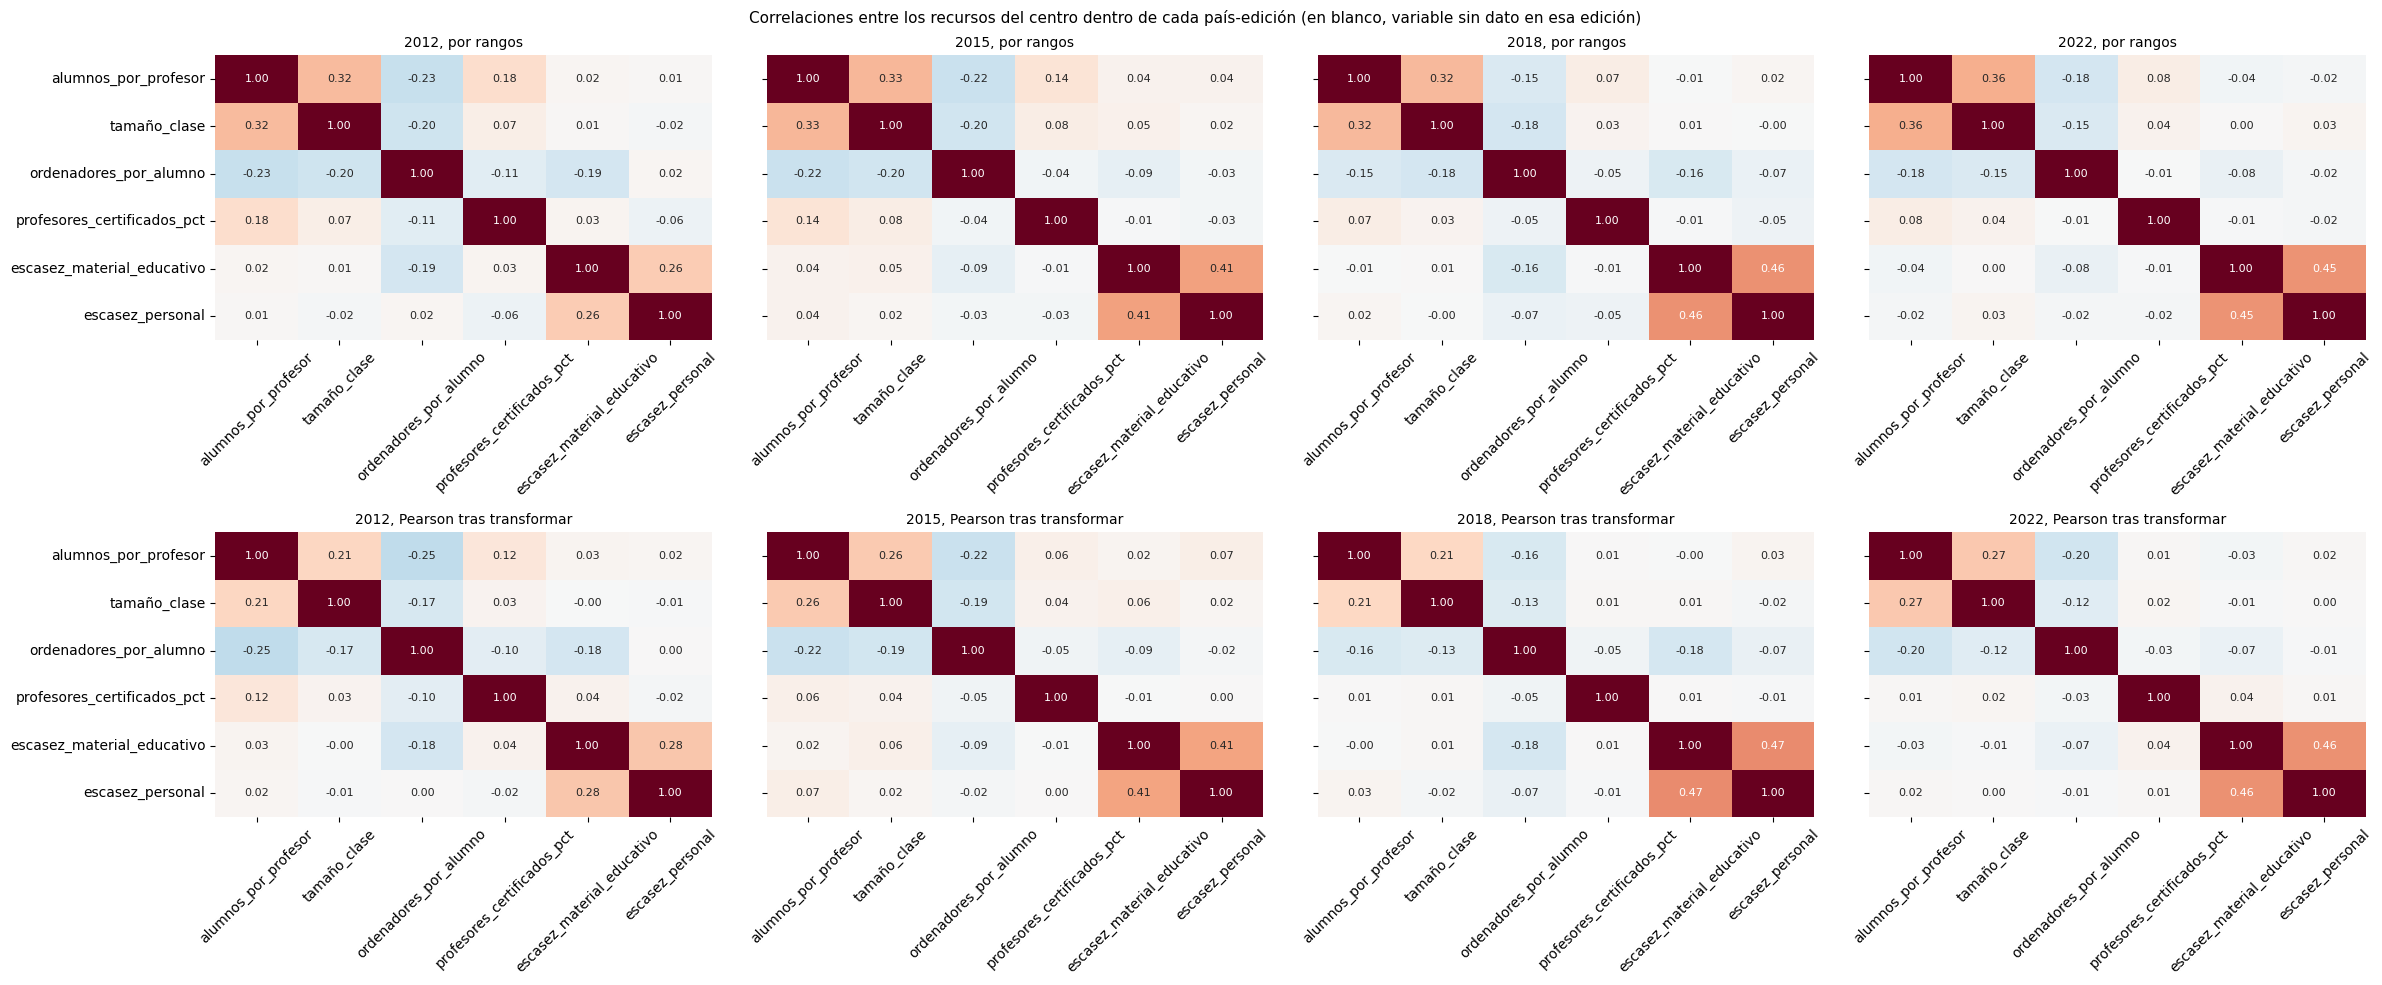

Alfa de Cronbach dentro de cada país-edición (variables estandarizadas):


,2012,2015,2018,2022
dotación (3 variables),0.452,0.450,0.365,0.408
escasez (2 variables),0.435,0.577,0.642,0.627


In [4]:
transformados = transformar_recursos(centros, CANDIDATAS)
rangos = centros[CANDIDATAS].groupby([centros[clave] for clave in GRUPO_PAIS_EDICION]).rank(pct=True)
centrados = centrar_en_grupos(transformados, CANDIDATAS, GRUPO_PAIS_EDICION)

fig, ejes = plt.subplots(2, len(EDICIONES), figsize=(24, 10), sharey=True)
for fila_ejes, (version, datos) in zip(ejes, [('por rangos', rangos), ('Pearson tras transformar', centrados)]):
    for eje, edicion in zip(fila_ejes, EDICIONES):
        sns.heatmap(datos[centros['year'] == edicion].corr(method='spearman' if version == 'por rangos' else 'pearson'), annot=True, fmt='.2f',
                    vmin=-1, vmax=1, cmap='RdBu_r', cbar=False, ax=eje, annot_kws={'fontsize': 8})
        eje.set_title(f'{edicion}, {version}', fontsize=10)
        eje.tick_params(axis='x', labelrotation=45)
fig.suptitle('Correlaciones entre los recursos del centro dentro de cada país-edición (en blanco, variable sin dato en esa edición)', fontsize=11)
plt.tight_layout()
fig.savefig(f'{RUTA_REPORTS}/01_recursos_centro_correlaciones.png', dpi=300, bbox_inches='tight')
plt.show()

# Coherencia interna (alfa de Cronbach) de las variables de dotación, con su signo (más = mejor dotado), y de las dos de escasez.
# Cada variable se divide antes por su desviación típica: con escalas tan distintas, el tamaño de clase dominaría el alfa.
def alfa_estandarizado(datos, items):
    return alfa_cronbach(datos[items] / datos[items].std(), items)


dotacion_con_signo = centrados[list(VARIABLES_DOTACION)] * pd.Series(VARIABLES_DOTACION)
alfas = pd.DataFrame({'dotación (3 variables)': {edicion: alfa_estandarizado(dotacion_con_signo[centros['year'] == edicion], list(VARIABLES_DOTACION)) for edicion in EDICIONES},
                      'escasez (2 variables)': {edicion: alfa_estandarizado(centrados[centros['year'] == edicion], VARIABLES_ESCASEZ) for edicion in EDICIONES}}).T
print('Alfa de Cronbach dentro de cada país-edición (variables estandarizadas):')
alfas.round(3)

**Qué se ve.**

* **Dos grupos de variables, y muy poco entre ellos.** Dentro de cada país-edición:
  * **dotación**: alumnos por profesor y tamaño de clase van juntos (por rangos, de 0,32 a 0,36), y los dos se oponen a los ordenadores por alumno (de −0,15 a −0,23). Es decir, los centros con más alumnos por profesor tienen clases más grandes y menos ordenadores por alumno;
  * **escasez según el director**: la de material y la de personal, de 0,41 a 0,46 en 2015-2022 y 0,26 en 2012, con las preguntas de esa edición;
  * entre los dos grupos, las correlaciones están entre −0,16 y 0,05.
* **El profesorado certificado no va con nada** (de −0,11 a 0,18), así que no se puede sumar a ningún grupo.
* **Las correlaciones son modestas**: el alfa de Cronbach de la dotación va de 0,365 a 0,452 y el de la escasez, de 0,577 a 0,642 en 2015-2022 y 0,435 en 2012. Las tres variables de dotación miden algo común, pero cada una tiene mucho de propio.
* **La transformación no cambia el dibujo**: tras el recorte y el logaritmo, las correlaciones de Pearson (de 0,21 a 0,27 entre alumnos por profesor y tamaño de clase) son algo más bajas que por rangos, con los mismos signos.

## 4. Índices

Con lo visto en la sección 3 se prueban dos índices (`construir_indices` de `src/recursos_centro.py`):

* **Dotación del centro** (`dotacion_centro`): alumnos por profesor y tamaño de clase (con signo negativo) y ordenadores por alumno, transformados y estandarizados con las cuatro ediciones juntas (cada país-edición pesa igual), para conservar las diferencias de nivel entre ediciones. Las ponderaciones son las de la primera componente principal de su variación dentro de cada país-edición, las mismas para todas las ediciones. Como comprobación, una versión con pesos iguales (`dotacion_centro_equiponderado`, media de las tres). Más alto = centro mejor dotado. Solo para centros con las tres variables.
* **Escasez según el director** (`escasez_centro`): media de la escasez de material y de personal (en 2012, de sus equivalentes; sección 9). Más alto = más escasez. La OCDE escala estos índices en cada edición por separado, así que su nivel no se puede comparar entre ediciones; solo dentro de cada una.

El % de profesorado certificado no entra en ninguno: no se relaciona con las demás variables y falta entera en Dinamarca y Hungría (sección 2).

Para ver si las ponderaciones son estables, se calcula también la componente principal de cada edición por separado.

In [5]:
centros, cargas, varianza_explicada = construir_indices(centros)
print(f'Primera componente principal de la dotación ({varianza_explicada:.1f} % de la varianza dentro de cada país-edición). Cargas:')
estandarizadas_dotacion = estandarizar_conjunto(transformar_recursos(centros, list(VARIABLES_DOTACION)), list(VARIABLES_DOTACION)) * pd.Series(VARIABLES_DOTACION)
cargas_por_edicion = {'todas las ediciones': {**cargas.round(3).to_dict(), '% varianza': round(varianza_explicada, 1)}}
for edicion in EDICIONES:
    en_edicion = centros['year'] == edicion
    cargas_edicion, varianza_edicion = cargas_primera_componente(estandarizadas_dotacion[en_edicion], centros.loc[en_edicion, GRUPO_PAIS_EDICION])
    cargas_por_edicion[edicion] = {**cargas_edicion.round(3).to_dict(), '% varianza': round(varianza_edicion, 1)}
display(pd.DataFrame(cargas_por_edicion))

print('% de centros con cada índice:')
display(centros.groupby('year')[INDICES].apply(lambda grupo: grupo.notna().mean().mul(100)).round(1))
print('Correlación entre las dos versiones de la dotación:', round(centros['dotacion_centro'].corr(centros['dotacion_centro_equiponderado']), 3),
      '| dentro de cada país-edición:', round(centrar_en_grupos(centros, INDICES[:2], GRUPO_PAIS_EDICION).corr().iloc[0, 1], 3))
centrados_indices = centrar_en_grupos(centros, ['dotacion_centro', 'escasez_centro'], GRUPO_PAIS_EDICION)
print('Correlación de la dotación con la escasez dentro de cada país-edición:', round(centrados_indices.corr().iloc[0, 1], 3), '| por edición:',
      {edicion: round(grupo.corr().iloc[0, 1], 3) for edicion, grupo in centrados_indices.groupby(centros['year'])})

Primera componente principal de la dotación (48.3 % de la varianza dentro de cada país-edición). Cargas:


,todas las ediciones,2012,2015,2018,2022
alumnos_por_profesor,0.534,0.506,0.538,0.573,0.483
tamaño_clase,0.665,0.722,0.669,0.691,0.500
ordenadores_por_alumno,0.522,0.473,0.513,0.441,0.719
% varianza,48.300,52.000,48.400,47.100,47.000


% de centros con cada índice:


,dotacion_centro,dotacion_centro_equiponderado,escasez_centro
year,,,
2012,85.5,85.5,95.6
2015,79.8,79.8,86.1
2018,83.4,83.4,92.4
2022,79.4,79.4,78.5


Correlación entre las dos versiones de la dotación: 0.996 | dentro de cada país-edición: 0.996
Correlación de la dotación con la escasez dentro de cada país-edición: -0.052 | por edición: {2012: np.float64(-0.056), 2015: np.float64(-0.074), 2018: np.float64(-0.071), 2022: np.float64(-0.01)}


**Qué se ve.**

* **La primera componente principal de la dotación explica el 48,3 % de la varianza** de las tres variables dentro de cada país-edición. Las tres pesan parecido: 0,534 alumnos por profesor, 0,665 tamaño de clase y 0,522 ordenadores por alumno.
* **Las ponderaciones son estables hasta 2018** (entre 0,44 y 0,72 según la variable y la edición, con un 47,0-52,0 % de varianza en cada edición). En 2022 los ordenadores pesan más (0,719) y el tamaño de clase menos (0,500), lo que puede venir del cambio de la pregunta de ordenadores.
* **La versión con pesos iguales es prácticamente la misma**: correlación de 0,996 con la de la componente principal, también dentro de cada país-edición. La elección del método no importa.
* **Cobertura**: la dotación existe para el 79,4-85,5 % de los centros, y la escasez para el 78,5-95,6 %.
* **Dotación y escasez son cosas distintas**: dentro de cada país-edición correlacionan −0,052 (entre −0,074 y −0,010 según la edición). Que un centro tenga clases pequeñas no dice nada de si su director declara que le falta material o personal.

## 5. Evolución por país

Media de cada recurso por país y edición, ponderada con el peso del centro (`W_SCHGRNRABWT`), en sus unidades originales (con el recorte de los extremos), y media del índice de dotación. La escasez no se muestra: su nivel no se compara entre ediciones (sección 4).

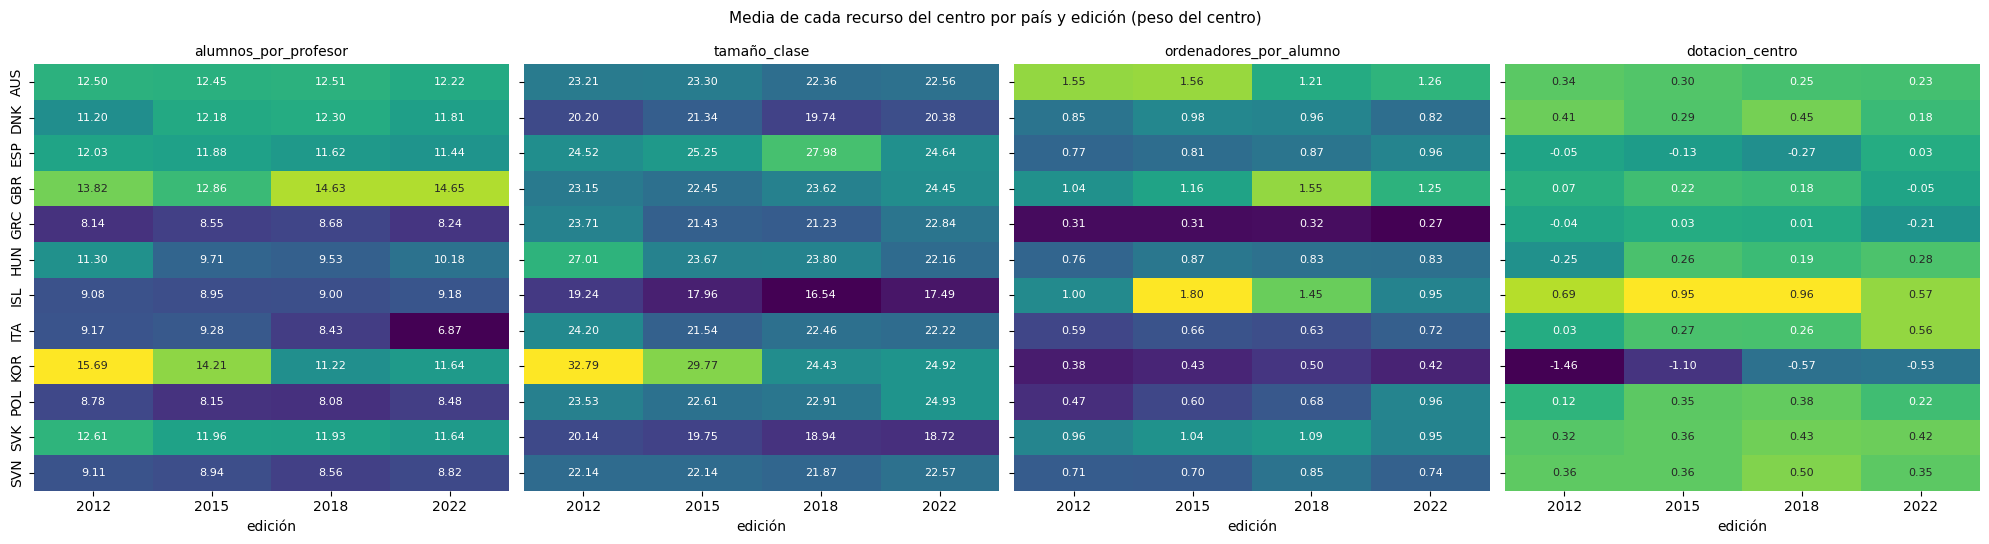

,media de los países en 2012,media de los países en 2022,país que más sube,país que más baja
alumnos_por_profesor,11.119357,10.430425,GBR (+0.83),KOR (-4.05)
tamaño_clase,23.653924,22.324083,POL (+1.40),KOR (-7.87)
ordenadores_por_alumno,0.781649,0.843412,POL (+0.49),AUS (-0.29)
dotacion_centro,0.045263,0.172195,KOR (+0.93),DNK (-0.23)


In [6]:
VARIABLES_EVOLUCION = list(VARIABLES_DOTACION) + ['dotacion_centro']
recortados = centros.copy()   # mismo recorte que en el índice, sin logaritmo, para leer las unidades originales
for variable in VARIABLES_DOTACION:
    inferior, superior = centros[variable].quantile([0.01, 0.99])
    recortados[variable] = centros[variable].clip(inferior, superior)
medias_pais = agregar_media_ponderada(recortados, VARIABLES_EVOLUCION, claves=['CNT', 'year'], peso_col='W_SCHGRNRABWT')
fig, ejes = plt.subplots(1, len(VARIABLES_EVOLUCION), figsize=(20, 5.5), sharey=True)
for eje, variable in zip(ejes, VARIABLES_EVOLUCION):
    sns.heatmap(medias_pais.pivot(index='CNT', columns='year', values=variable), annot=True, fmt='.2f', cmap='viridis', cbar=False, ax=eje, annot_kws={'fontsize': 8})
    eje.set_title(variable, fontsize=10)
    eje.set_xlabel('edición')
    eje.set_ylabel('')
fig.suptitle('Media de cada recurso del centro por país y edición (peso del centro)', fontsize=11)
plt.tight_layout()
fig.savefig(f'{RUTA_REPORTS}/01_recursos_centro_evolucion_pais.png', dpi=300, bbox_inches='tight')
plt.show()
cambio = medias_pais.pivot(index='CNT', columns='year', values=VARIABLES_EVOLUCION)
pd.DataFrame({variable: {'media de los países en 2012': cambio[(variable, 2012)].mean(), 'media de los países en 2022': cambio[(variable, 2022)].mean(),
                         'país que más sube': f'{(cambio[(variable, 2022)] - cambio[(variable, 2012)]).idxmax()} ({(cambio[(variable, 2022)] - cambio[(variable, 2012)]).max():+.2f})',
                         'país que más baja': f'{(cambio[(variable, 2022)] - cambio[(variable, 2012)]).idxmin()} ({(cambio[(variable, 2022)] - cambio[(variable, 2012)]).min():+.2f})'}
              for variable in VARIABLES_EVOLUCION}).T

**Qué se ve.**

* **La dotación mejora algo entre 2012 y 2022**: de media entre los 12 países, los alumnos por profesor bajan de 11,12 a 10,43 y el tamaño de clase de 23,65 a 22,32. Los ordenadores por alumno suben de 0,78 a 0,84.
* **Corea explica buena parte del cambio**: los alumnos por profesor bajan 4,05 y el tamaño de clase 7,87 (de 32,79 a 24,92 alumnos por clase), y su índice de dotación sube 0,93, el que más. Italia también mejora mucho en alumnos por profesor (de 9,17 a 6,87).
* **Los niveles entre países son muy distintos**: Grecia tiene unos 0,3 ordenadores por alumno en todas las ediciones, y Australia entre 1,21 y 1,56. Islandia es el país mejor dotado según el índice (de 0,57 a 0,96).

## 6. Dónde está la variación

Con los alumnos (cada país-edición pesa igual, con `SENWT`), la varianza de cada variable se reparte en cinco partes anidadas (`reparto_varianza`): entre países, entre ediciones de un mismo país, entre perfiles de centro de un mismo país-edición, entre centros de un mismo perfil y entre alumnos de un mismo centro. Los recursos del centro son iguales para todos sus alumnos, así que su última parte es 0. La parte entre perfiles dice cuánto de cada recurso ya recoge el tipo de centro; la parte entre centros del mismo perfil es la que queda para compararlos dentro de él. Para comparar, lo mismo con la nota de matemáticas (con cada valor plausible), los recursos de estudio, el compromiso y la composición social del centro.

Después, la media de los índices en cada perfil (de media entre países, cada uno pesando igual).

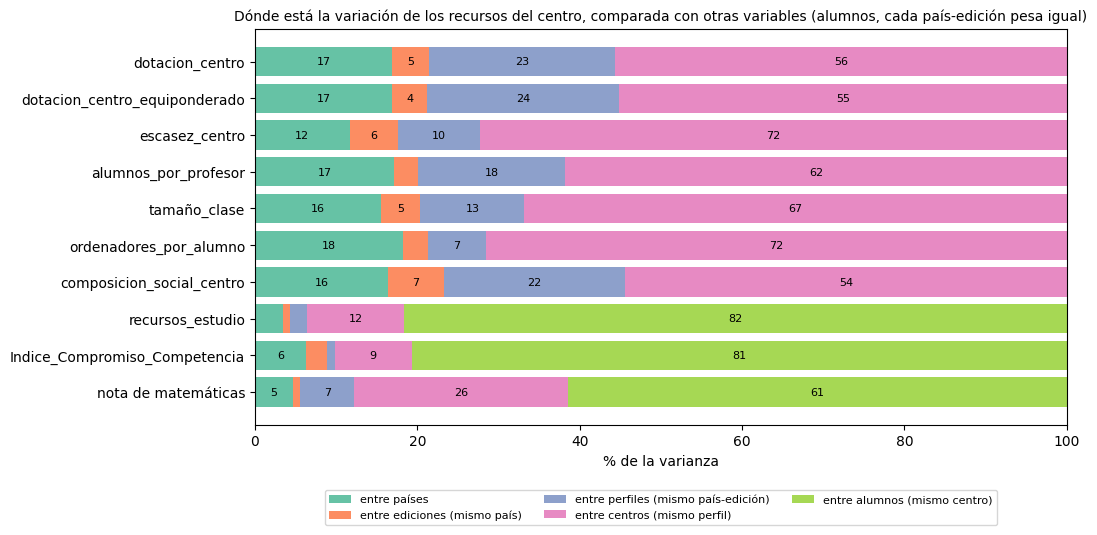

,entre países,entre ediciones (mismo país),entre perfiles (mismo país-edición),entre centros (mismo perfil),entre alumnos (mismo centro)
dotacion_centro,16.9,4.5,22.9,55.6,0.0
dotacion_centro_equiponderado,16.9,4.4,23.6,55.2,0.0
escasez_centro,11.7,5.9,10.2,72.2,0.0
alumnos_por_profesor,17.2,3.0,18.0,61.8,0.0
tamaño_clase,15.5,4.8,12.8,66.8,0.0
ordenadores_por_alumno,18.2,3.1,7.1,71.6,0.0
composicion_social_centro,16.4,6.8,22.4,54.4,0.0
recursos_estudio,3.5,0.9,2.1,11.9,81.7
Indice_Compromiso_Competencia,6.3,2.6,0.9,9.5,80.7
nota de matemáticas,4.6,0.9,6.6,26.4,61.4


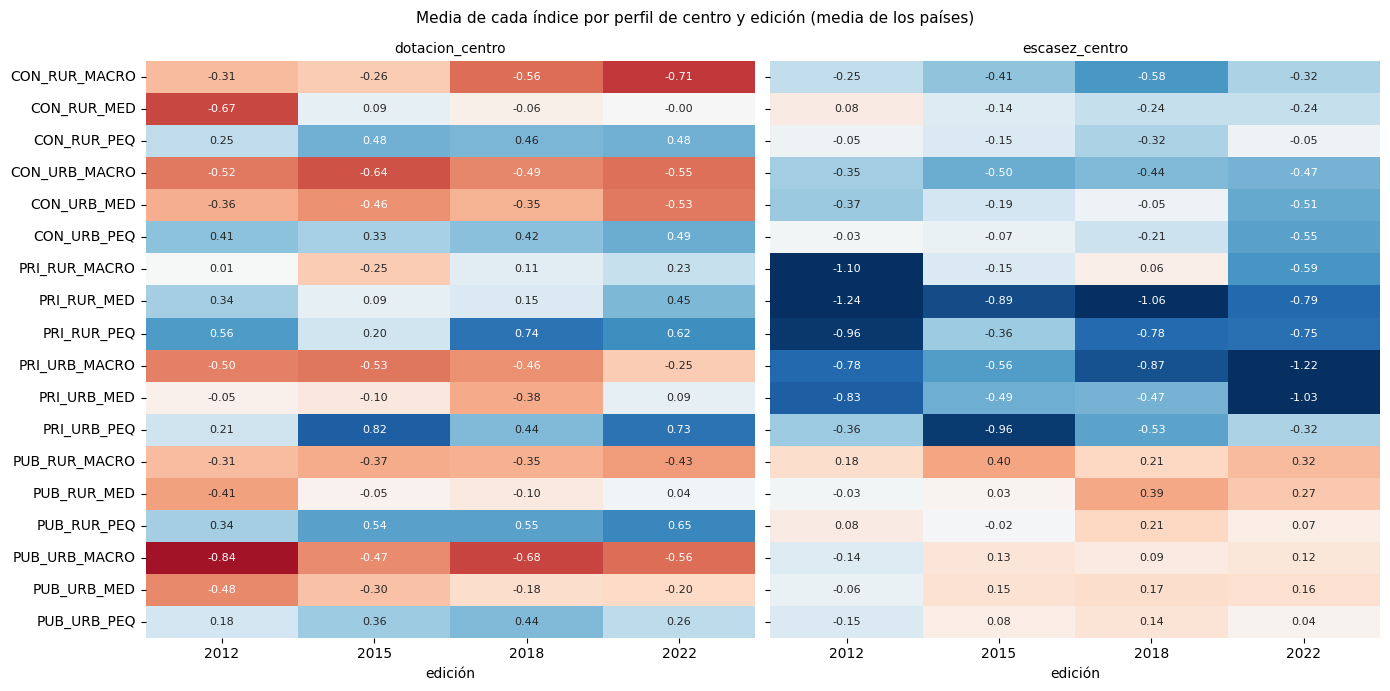

In [7]:
alumnos = alumnos.merge(centros[['CNT', 'CNTSCHID', 'year'] + list(VARIABLES_DOTACION) + VARIABLES_ESCASEZ + INDICES], on=['CNT', 'CNTSCHID', 'year'], how='left', validate='many_to_one')
NIVELES = {'entre países': ['CNT'], 'entre ediciones (mismo país)': ['CNT', 'year'], 'entre perfiles (mismo país-edición)': ['CNT', 'year', 'perfil'],
           'entre centros (mismo perfil)': ['CNT', 'year', 'perfil', 'CNTSCHID']}
RESIDUO = 'entre alumnos (mismo centro)'


def reparto_alumnos(datos, columna):
    return reparto_varianza(datos, columna, NIVELES, RESIDUO, peso_col='SENWT')


VARIABLES_REPARTO = INDICES + list(VARIABLES_DOTACION) + ['composicion_social_centro', 'recursos_estudio', 'Indice_Compromiso_Competencia']
reparto = pd.DataFrame({**{variable: reparto_alumnos(alumnos, variable) for variable in VARIABLES_REPARTO},
                        'nota de matemáticas': estimar_con_pv(alumnos, 'MATH', reparto_alumnos)}).T
fig, ax = plt.subplots(figsize=(11, 5.5))
izquierda = np.zeros(len(reparto))
for nivel, color in zip(reparto.columns, sns.color_palette('Set2', n_colors=len(reparto.columns))):
    barras = ax.barh(reparto.index[::-1], reparto[nivel][::-1], left=izquierda[::-1], color=color, label=nivel)
    ax.bar_label(barras, labels=[f'{valor:.0f}' if valor >= 4 else '' for valor in reparto[nivel][::-1]], label_type='center', fontsize=8)
    izquierda += reparto[nivel].to_numpy()
ax.set_xlabel('% de la varianza')
ax.set_title('Dónde está la variación de los recursos del centro, comparada con otras variables (alumnos, cada país-edición pesa igual)', fontsize=10)
ax.legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.15), ncols=3)
plt.tight_layout()
fig.savefig(f'{RUTA_REPORTS}/01_recursos_centro_reparto_varianza.png', dpi=300, bbox_inches='tight')
plt.show()
display(reparto.round(1))

# Media de cada índice por perfil y edición: media por país-perfil (con SENWT) y después media de los países
media_perfil = (agregar_media_ponderada(alumnos, INDICES, claves=['CNT', 'year', 'perfil'], peso_col='SENWT')
                .groupby(['perfil', 'year'])[INDICES].mean())
fig, ejes = plt.subplots(1, 2, figsize=(14, 7), sharey=True)
for eje, indice in zip(ejes, ['dotacion_centro', 'escasez_centro']):
    sns.heatmap(media_perfil[indice].unstack('year'), annot=True, fmt='.2f', cmap='RdBu_r' if indice == 'escasez_centro' else 'RdBu', center=0, vmin=-1, vmax=1,
                cbar=False, ax=eje, annot_kws={'fontsize': 8})
    eje.set_title(indice, fontsize=10)
    eje.set_xlabel('edición')
    eje.set_ylabel('')
fig.suptitle('Media de cada índice por perfil de centro y edición (media de los países)', fontsize=11)
plt.tight_layout()
fig.savefig(f'{RUTA_REPORTS}/01_recursos_centro_perfiles.png', dpi=300, bbox_inches='tight')
plt.show()

**Qué se ve.**

* **La dotación varía sobre todo entre centros del mismo perfil** (55,6 %). El perfil recoge una parte importante (22,9 %), más que en la escasez (10,2 %) o en los ordenadores (7,1 %). Entre países está el 16,9 % y entre ediciones de un mismo país, el 4,5 %.
* **Es un reparto muy parecido al de la composición social del centro** (22,4 % entre perfiles y 54,4 % entre centros del mismo perfil).
* **Al contrario que las variables del alumno**: el 81,7 % de la varianza de los recursos de estudio y el 80,7 % de la del compromiso está entre alumnos del mismo centro. Los recursos del centro solo se pueden comparar entre centros: dentro de un perfil de un país-edición hay pocos centros, así que su relación con la nota se estimará con mucha menos información que la de las variables del alumno.
* **Por perfil**, los centros pequeños están mejor dotados, en los tres tipos de titularidad (por ejemplo, de 0,34 a 0,65 los públicos rurales pequeños), y los grandes urbanos, peor (de −0,47 a −0,84 los públicos urbanos grandes). Es lo esperable: en un centro pequeño hay menos alumnos por profesor y clases más pequeñas. En escasez, los públicos declaran más (de −0,15 a 0,40) y los privados y concertados, en general menos (hasta −1,24).

## 7. Relación con la composición social y con las variables del alumno

Correlaciones dentro de cada país-edición entre los índices del centro, la composición social del centro (`composicion_social_centro`, `01_EDA_variables_modelo`), el origen social del alumno (ocupación de los padres, `HISEI_TREND`), sus recursos de estudio, su compromiso y su nota de matemáticas (con cada valor plausible). Cada alumno pesa con `SENWT`. Interesa sobre todo:

* si los centros que atienden a alumnos más favorecidos están mejor o peor dotados (si están peor, hay compensación);
* si los recursos del centro se solapan con las variables del alumno que el modelo ya incluye.

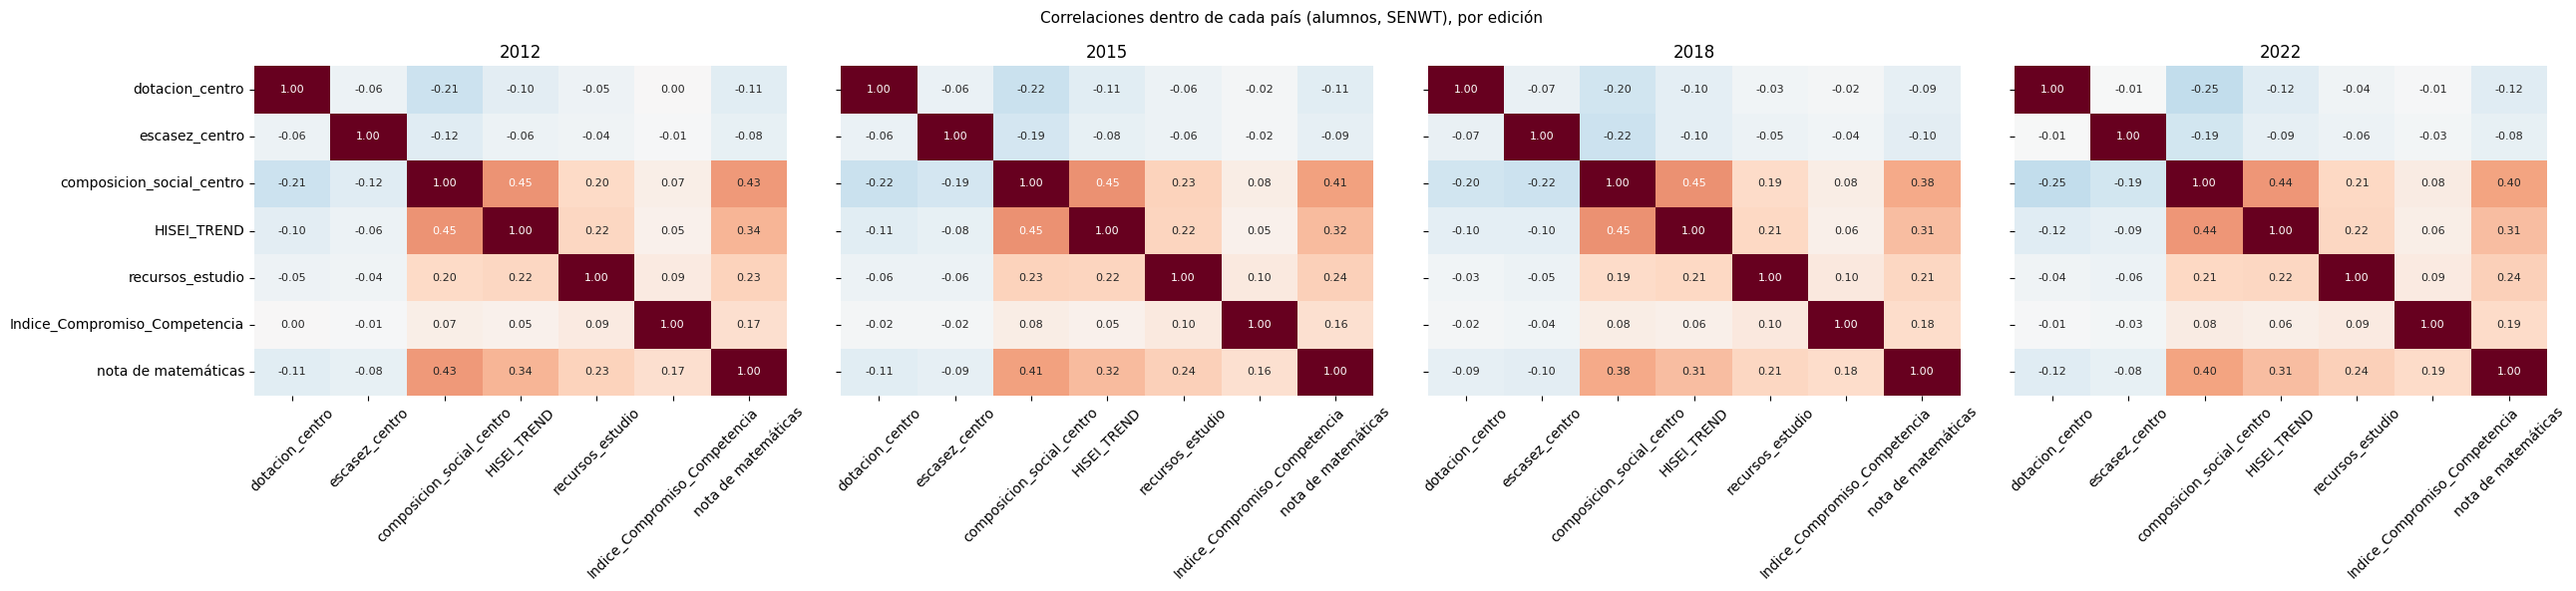

In [8]:
VARIABLES_RELACION = ['dotacion_centro', 'escasez_centro', 'composicion_social_centro', 'HISEI_TREND', 'recursos_estudio', 'Indice_Compromiso_Competencia']


def correlaciones_con_nota(datos, columna_nota):
    centradas = centrar_en_grupos(datos, VARIABLES_RELACION + [columna_nota], ['CNT'], peso_col='SENWT')
    return centradas.rename(columns={columna_nota: 'nota de matemáticas'}).corr()


fig, ejes = plt.subplots(1, len(EDICIONES), figsize=(26, 6), sharey=True)
for eje, (edicion, grupo) in zip(ejes, alumnos.groupby('year')):
    sns.heatmap(estimar_con_pv(grupo, 'MATH', correlaciones_con_nota), annot=True, fmt='.2f', vmin=-1, vmax=1, cmap='RdBu_r', cbar=False, ax=eje, annot_kws={'fontsize': 8})
    eje.set_title(str(edicion))
    eje.tick_params(axis='x', labelrotation=45)
fig.suptitle('Correlaciones dentro de cada país (alumnos, SENWT), por edición', fontsize=11)
plt.tight_layout()
fig.savefig(f'{RUTA_REPORTS}/01_recursos_centro_correlaciones_alumno.png', dpi=300, bbox_inches='tight')
plt.show()

**Qué se ve.**

* **Los centros mejor dotados atienden a alumnos menos favorecidos**: la dotación correlaciona entre −0,20 y −0,25 con la composición social del centro, dentro de cada país. Hay compensación: menos alumnos por profesor y clases más pequeñas donde los alumnos son más desfavorecidos.
* **Los directores de centros menos favorecidos declaran más escasez**: entre −0,19 y −0,22 con la composición social en 2015-2022, y −0,12 en 2012 (sección 9).
* **Por eso los dos índices correlacionan negativamente con la nota** (dotación, entre −0,09 y −0,12; escasez, entre −0,08 y −0,10 en 2015-2022). En el caso de la dotación, el signo es el contrario al de un efecto positivo de los recursos.
* **Casi no se solapan con las variables del alumno**: con los recursos de estudio y el compromiso, entre −0,06 y 0,00. Meterlos en el modelo no cambiaría las pendientes del alumno por solapamiento.

## 8. Relación con la nota

Regresión de la nota de matemáticas dentro de cada país-edición (`regresion_dentro_de_grupos`, con `SENWT` y cada valor plausible por separado): cuántos puntos se asocian a una desviación típica de cada recurso del centro, con cada variable por separado y en cuatro modelos que añaden controles:

1. **solo**: el recurso, sin nada más;
2. **con la composición social del centro**;
3. **con la composición social y las variables del alumno**: origen social (`HISEI_TREND`, `PAREDINT_TREND`), recursos de estudio y compromiso. Es lo más parecido al modelo del TFM;
4. **lo mismo, dentro de cada perfil**: compara centros del mismo país-edición y del mismo perfil, como hará el modelo.

Es descriptiva: asociaciones, no efectos. Los modelos 3 y 4 solo usan alumnos con todas las variables (el compromiso deja fuera a cerca de una cuarta parte, `01_EDA_indice_de_compromiso_competencia`).

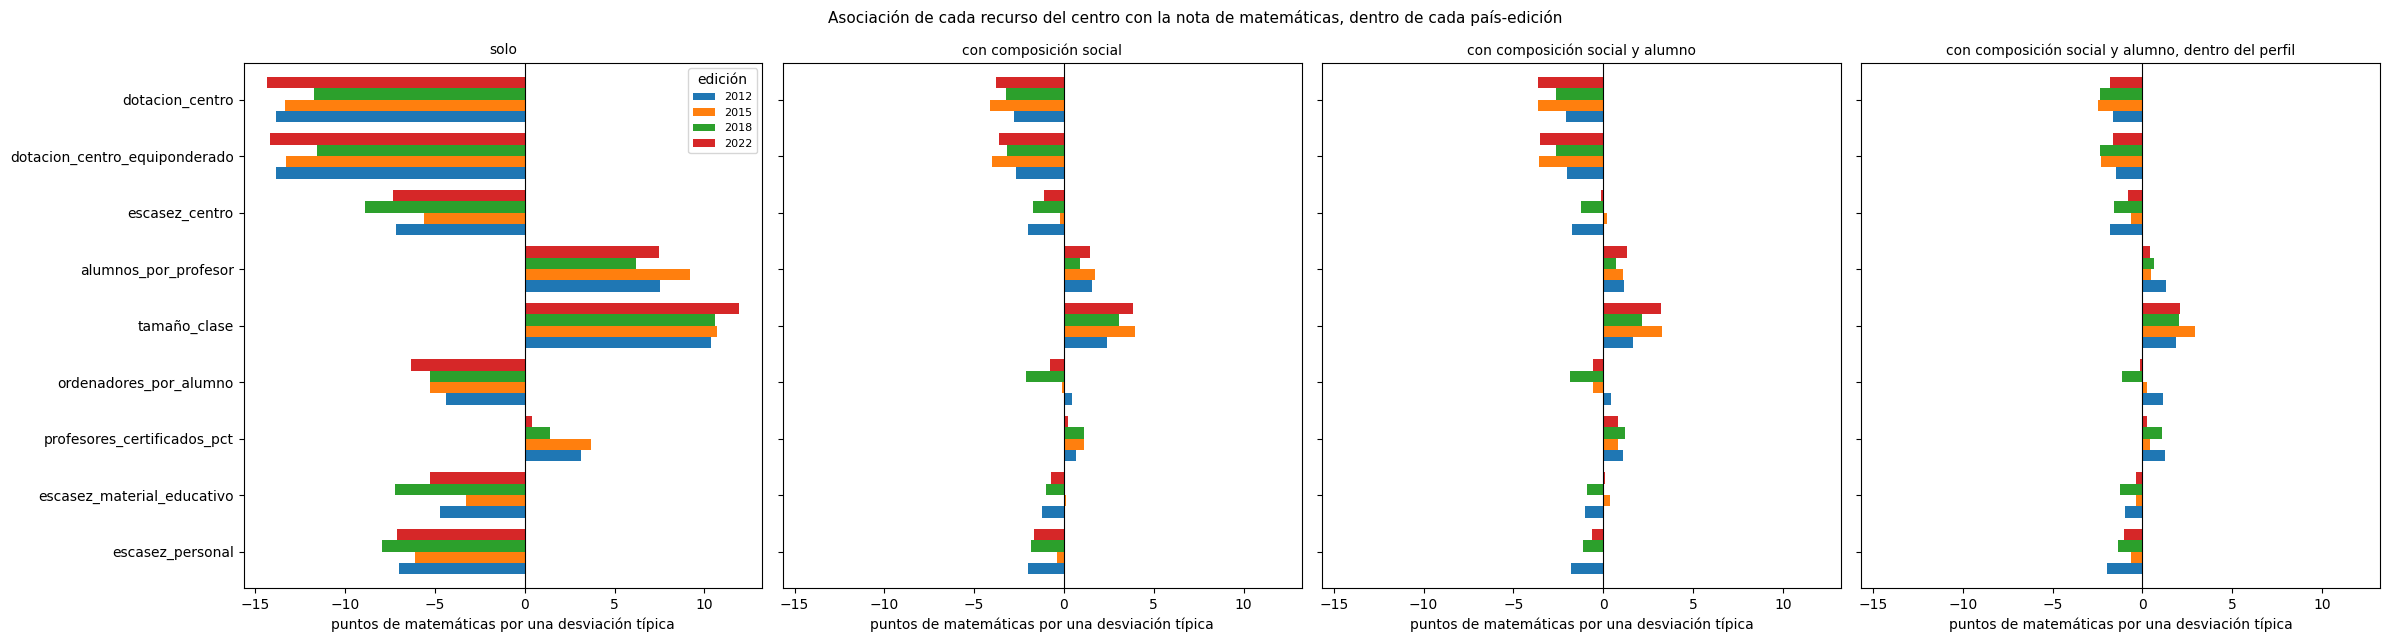

modelo                        con composición social                con composición social y alumno                con composición social y alumno, dentro del perfil                 solo        \
edición                                         2012 2015 2018 2022                            2012 2015 2018 2022                                               2012 2015 2018 2022  2012  2015   
variable                                                                                                                                                                                           
dotacion_centro                                 -2.8 -4.1 -3.2 -3.8                            -2.1 -3.7 -2.6 -3.7                                               -1.6 -2.5 -2.4 -1.8 -13.9 -13.3   
dotacion_centro_equiponderado                   -2.7 -4.0 -3.2 -3.6                            -2.0 -3.6 -2.6 -3.5                                               -1.5 -2.3 -2.4 -1.7 -13.9 -13.3   
escasez_centro                                  -2.0 -0.2 -1.7 -1.1                            -1.7  0.2 -1.2 -0.1                                               -1.8 -0.6 -1.6 -0.8  -7.2  -5.6   
alumnos_por_profesor                             1.6  1.7  0.9  1.4                             1.2  1.1  0.7  1.3                                                1.3  0.5  0.6  0.4   7.5   9.2   
tamaño_clase                                     2.4  4.0  3.0  3.9                             1.7  3.3  2.2  3.2                                                1.9  2.9  2.0  2.1  10.4  10.7   
ordenadores_por_alumno                           0.4 -0.1 -2.1 -0.8                             0.5 -0.6 -1.9 -0.6                                                1.2  0.2 -1.1 -0.1  -4.4  -5.3   
profesores_certificados_pct                      0.7  1.1  1.1  0.2                             1.1  0.8  1.2  0.8                                                1.2  0.4  1.1  0.3   3.1   3.7   
escasez_material_educativo                      -1.2  0.1 -1.0 -0.7                            -1.0  0.4 -0.9  0.1                                               -1.0 -0.3 -1.2 -0.3  -4.7  -3.3   
escasez_personal                                -2.0 -0.4 -1.8 -1.7                            -1.8  0.1 -1.1 -0.6                                               -2.0 -0.6 -1.4 -1.1  -7.0  -6.1   

modelo                                     
edición                        2018  2022  
variable                                   
dotacion_centro               -11.7 -14.3  
dotacion_centro_equiponderado -11.6 -14.2  
escasez_centro                 -8.9  -7.3  
alumnos_por_profesor            6.2   7.5  
tamaño_clase                   10.6  11.9  
ordenadores_por_alumno         -5.3  -6.3  
profesores_certificados_pct     1.4   0.4  
escasez_material_educativo     -7.2  -5.3  
escasez_personal               -7.9  -7.1

Alumnos en cada modelo (dotación del centro):


edición,2012,2015,2018,2022
modelo,,,,
solo,105957,74436,104907,94749
con composición social,105931,74356,104382,94518
con composición social y alumno,65165,62398,64406,74020
"con composición social y alumno, dentro del perfil",65165,62398,64406,74020


In [9]:
CONTROLES = {'solo': [], 'con composición social': ['composicion_social_centro'],
             'con composición social y alumno': ['composicion_social_centro', 'HISEI_TREND', 'PAREDINT_TREND', 'recursos_estudio', 'Indice_Compromiso_Competencia']}
MODELOS = {**{nombre: (controles, ['CNT']) for nombre, controles in CONTROLES.items()},
           'con composición social y alumno, dentro del perfil': (CONTROLES['con composición social y alumno'], ['CNT', 'perfil'])}
VARIABLES_NOTA = INDICES + list(VARIABLES_DOTACION) + ['profesores_certificados_pct'] + VARIABLES_ESCASEZ
alumnos = alumnos.merge(centros[['CNT', 'CNTSCHID', 'year', 'profesores_certificados_pct']], on=['CNT', 'CNTSCHID', 'year'], how='left', validate='many_to_one')

filas = []
for edicion, grupo in alumnos.groupby('year'):
    for variable in VARIABLES_NOTA:
        if grupo[variable].isna().all():
            continue
        for modelo, (controles, claves) in MODELOS.items():
            ajuste = estimar_con_pv(grupo, 'MATH', lambda datos, columna: regresion_dentro_de_grupos(datos, columna, [variable] + controles, claves, peso_col='SENWT'))
            filas.append({'edición': edicion, 'variable': variable, 'modelo': modelo, 'puntos por desviación típica': ajuste.loc[variable, 'por desviación típica'],
                          'alumnos': int(ajuste['filas'].iloc[0])})
asociacion = pd.DataFrame(filas)

fig, ejes = plt.subplots(1, len(MODELOS), figsize=(24, 6.5), sharey=True, sharex=True)
for eje, modelo in zip(ejes, MODELOS):
    tabla = asociacion[asociacion['modelo'] == modelo].pivot(index='variable', columns='edición', values='puntos por desviación típica').reindex(VARIABLES_NOTA[::-1])
    tabla.plot.barh(ax=eje, width=0.8, legend=(eje is ejes[0]))
    eje.axvline(0, color='black', lw=0.8)
    eje.set_title(modelo, fontsize=10)
    eje.set_ylabel('')
    eje.set_xlabel('puntos de matemáticas por una desviación típica')
ejes[0].legend(fontsize=8, title='edición')
fig.suptitle('Asociación de cada recurso del centro con la nota de matemáticas, dentro de cada país-edición', fontsize=11)
plt.tight_layout()
fig.savefig(f'{RUTA_REPORTS}/01_recursos_centro_asociacion_nota.png', dpi=300, bbox_inches='tight')
plt.show()
display(asociacion.pivot_table(index='variable', columns=['modelo', 'edición'], values='puntos por desviación típica').reindex(VARIABLES_NOTA).round(1))
print('Alumnos en cada modelo (dotación del centro):')
asociacion[asociacion['variable'] == 'dotacion_centro'].pivot(index='modelo', columns='edición', values='alumnos').reindex(list(MODELOS))

**Qué se ve.**

* **Solos, los recursos del centro se asocian a la nota con el signo contrario al esperado**: una desviación típica más de dotación, entre 11,7 y 14,3 puntos menos; y una más de alumnos por profesor o de tamaño de clase, entre 6,2 y 11,9 puntos más. Es la compensación de la sección 7: los centros con clases pequeñas atienden a alumnos más desfavorecidos.
* **Con la composición social del centro, la asociación casi desaparece**: la dotación pasa a entre −2,8 y −4,1 puntos, y la escasez a entre −0,2 y −2,0.
* **Con las variables del alumno y dentro del perfil quedan pocos puntos**: la dotación, entre −1,6 y −2,5; la escasez, entre −0,6 y −1,8; el profesorado certificado, entre 0,3 y 1,2. Para comparar, los recursos de estudio del alumno se asocian a entre 6,8 y 8,9 puntos por desviación típica con controles parecidos (`01_EDA_recursos_alumno`).
* **No hay un cambio claro entre ediciones**: en el modelo más completo, la dotación da −1,6, −2,5, −2,4 y −1,8 puntos.
* Los modelos con las variables del alumno usan entre 62.398 y 74.020 alumnos por edición, sobre todo por los que no tienen índice de compromiso.

Un coeficiente negativo de la dotación, incluso con controles, no significa que los recursos perjudiquen. Lo más probable es que los centros reciban más recursos porque sus alumnos los necesitan, por motivos que la composición social no recoge del todo (alumnos con necesidades educativas, repetidores, programas de compensación). Con datos de un solo momento por centro no se puede separar el efecto de los recursos de la forma en que se reparten.

## 9. La escasez de 2012 frente a la de 2015-2022

En 2012 la escasez se mide con otras preguntas (sección 1): la calidad de los recursos educativos (`SCMATEDU`, con el signo cambiado) en lugar de la escasez de material (`EDUSHORT`), y la escasez de profesores de matemáticas, ciencias y lengua (`TCSHORT`) en lugar de la escasez de personal, que incluye también al personal de apoyo (`STAFFSHORT`). Como la escasez solo compara centros de una misma edición, que la escala sea otra no importa; lo que importa es que se comporte igual. Se resumen por edición las relaciones que ya se han visto (todas dentro de cada país-edición): entre sus dos componentes, con la dotación, con la composición social del centro (alumnos, `SENWT`) y con la nota de matemáticas, sola y con todos los controles dentro del perfil (sección 8). Si 2012 se parece a las demás ediciones, la escasez entra en las cuatro.

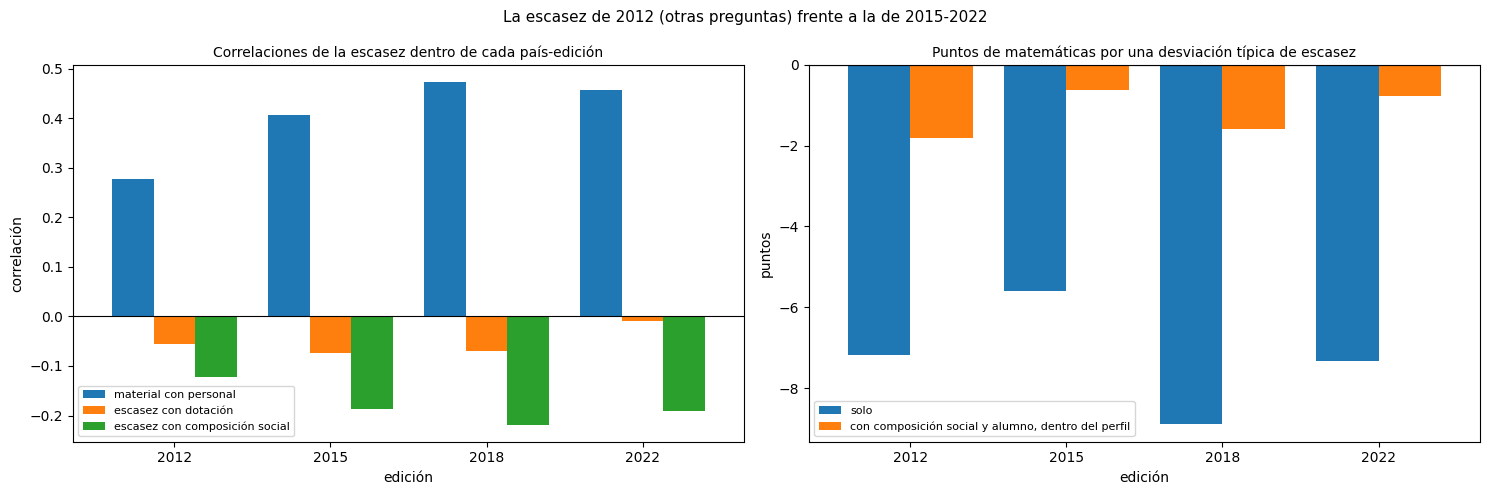

,material con personal,escasez con dotación,escasez con composición social,solo,"con composición social y alumno, dentro del perfil"
2012,0.28,-0.06,-0.12,-7.18,-1.81
2015,0.41,-0.07,-0.19,-5.60,-0.61
2018,0.47,-0.07,-0.22,-8.88,-1.58
2022,0.46,-0.01,-0.19,-7.32,-0.78


In [10]:
correlaciones_escasez = {}
for edicion in EDICIONES:
    centros_edicion = centros['year'] == edicion
    alumnos_edicion = alumnos[alumnos['year'] == edicion]
    centrados_alumnos = centrar_en_grupos(alumnos_edicion, ['escasez_centro', 'composicion_social_centro'], ['CNT'], peso_col='SENWT')
    correlaciones_escasez[edicion] = {
        'material con personal': centrados.loc[centros_edicion, VARIABLES_ESCASEZ].corr().iloc[0, 1],
        'escasez con dotación': centrados_indices.loc[centros_edicion].corr().iloc[0, 1],
        'escasez con composición social': centrados_alumnos.corr().iloc[0, 1],
    }
correlaciones_escasez = pd.DataFrame(correlaciones_escasez).T
asociacion_escasez = (asociacion[asociacion['variable'] == 'escasez_centro']
                      .pivot(index='edición', columns='modelo', values='puntos por desviación típica')[['solo', 'con composición social y alumno, dentro del perfil']])

fig, ejes = plt.subplots(1, 2, figsize=(15, 5))
correlaciones_escasez.plot.bar(ax=ejes[0], rot=0, width=0.8)
ejes[0].set_title('Correlaciones de la escasez dentro de cada país-edición', fontsize=10)
ejes[0].set_ylabel('correlación')
asociacion_escasez.plot.bar(ax=ejes[1], rot=0, width=0.8)
ejes[1].set_title('Puntos de matemáticas por una desviación típica de escasez', fontsize=10)
ejes[1].set_ylabel('puntos')
for eje in ejes:
    eje.axhline(0, color='black', lw=0.8)
    eje.set_xlabel('edición')
    eje.legend(fontsize=8)
fig.suptitle('La escasez de 2012 (otras preguntas) frente a la de 2015-2022', fontsize=11)
plt.tight_layout()
fig.savefig(f'{RUTA_REPORTS}/01_recursos_centro_escasez_2012.png', dpi=300, bbox_inches='tight')
plt.show()
pd.concat([correlaciones_escasez, asociacion_escasez], axis=1).round(2)

**Qué se ve.**

* **2012 se comporta como las demás ediciones, aunque con relaciones algo más débiles**:
  * sus dos componentes van juntos, pero menos: 0,28 frente a 0,41-0,47 (son preguntas más estrechas: profesores de tres materias y material sin infraestructura);
  * la escasez casi no tiene relación con la dotación, como en el resto de ediciones (−0,06, frente a −0,01 a −0,07);
  * los directores de centros menos favorecidos declaran más escasez: −0,12 con la composición social, frente a −0,19 a −0,22.
* **Con la nota, lo mismo que en 2015-2022**: sola, una desviación típica más de escasez se asocia a 7,2 puntos menos (de 5,6 a 8,9 en el resto); con todos los controles y dentro del perfil, a 1,8 menos (de 0,6 a 1,6).

La escasez de 2012 puede entrar en el modelo junto a la de las demás ediciones. Como en todas, solo compara centros de la misma edición.

## 10. Alumnos de centros sin índice

% de alumnos cuyo centro no tiene cada índice y su nota de matemáticas (media de sus valores plausibles) respecto a la media de su país-edición, con `SENWT`. Si los alumnos de centros sin dato sacan una nota distinta, quitarlos sesgaría la muestra.

In [11]:
alumnos['nota_relativa'] = centrar_en_grupos(alumnos.assign(nota=alumnos[[f'PV{numero}MATH' for numero in range(1, 6)]].mean(axis=1)), ['nota'], ['CNT', 'year'], peso_col='SENWT')['nota']
filas = {}
for indice in ['dotacion_centro', 'escasez_centro']:
    for edicion, grupo in alumnos.groupby('year'):
        sin_dato = grupo[indice].isna()
        if sin_dato.all():
            continue
        filas[(indice, edicion)] = {'% de alumnos sin índice': 100 * sin_dato.mean(),
                                    'nota relativa, con índice': np.average(grupo.loc[~sin_dato, 'nota_relativa'], weights=grupo.loc[~sin_dato, 'SENWT']),
                                    'nota relativa, sin índice': np.average(grupo.loc[sin_dato, 'nota_relativa'], weights=grupo.loc[sin_dato, 'SENWT']) if sin_dato.any() else np.nan}
display(pd.DataFrame(filas).T.round(1))
print('% de alumnos sin dotación del centro, por país y edición:')
alumnos.groupby(['CNT', 'year'])['dotacion_centro'].apply(lambda serie: round(100 * serie.isna().mean(), 1)).unstack('year')

% de alumnos sin índice  nota relativa, con índice  nota relativa, sin índice
dotacion_centro 2012                      8.5                       -0.4                        4.8
                2015                      4.7                        0.5                      -10.5
                2018                      4.6                        1.0                      -19.5
                2022                      9.8                        0.8                       -7.9
escasez_centro  2012                      0.7                        0.1                      -15.6
                2015                      1.3                        0.0                       -1.6
                2018                      1.2                       -0.1                       10.4
                2022                     16.5                        0.3                       -1.2

% de alumnos sin dotación del centro, por país y edición:


year,2012,2015,2018,2022
CNT,,,,
AUS,5.4,7.8,8.7,19.3
DNK,7.1,5.3,2.6,11.9
ESP,13.9,2.4,2.2,7.8
GBR,9.4,8.4,10.8,25.2
GRC,10.0,2.6,2.3,2.6
HUN,0.4,2.6,4.2,3.6
ISL,12.4,9.7,6.4,19.9
ITA,7.9,2.1,5.3,4.9
KOR,1.9,0.0,1.2,1.9


**Qué se ve.**

* **Pocos alumnos se quedan sin dotación del centro**: entre el 4,6 % y el 9,8 % según la edición, con más huecos en 2022 en Reino Unido (25,2 %), Islandia (19,9 %) y Australia (19,3 %).
* **Sin escasez se queda el 16,5 % en 2022**, por Corea y Eslovaquia (sección 2); en 2012, 2015 y 2018, del 0,7 % al 1,3 %.
* **Los alumnos de centros sin dotación sacan una nota distinta, pero sin un sentido fijo**: 4,8 puntos más que la media de su país en 2012 y entre 7,9 y 19,5 menos en 2015-2022. Si la dotación entra en el modelo como control, conviene añadir un indicador de «sin dato» en lugar de quitar a esos alumnos (la misma regla que el resto de los controles).

## Hallazgos

* **Los recursos del centro no forman un único índice.** Hay dos grupos que casi no se relacionan entre sí (−0,052): la **dotación** (alumnos por profesor, tamaño de clase y ordenadores por alumno, en las cuatro ediciones) y la **escasez según el director** (de material y de personal; en 2012, con otras preguntas). El profesorado certificado no va con ninguno y falta en Dinamarca y Hungría.
* **El índice de dotación es débil pero estable**: la primera componente principal explica el 48,3 % de la varianza (alfa de 0,365 a 0,452), las tres variables pesan parecido, y la versión con pesos iguales es casi idéntica (0,996).
* **Hay compensación**: los centros con alumnos menos favorecidos tienen menos alumnos por profesor y clases más pequeñas (−0,20 a −0,25 con la composición social), y sus directores declaran más escasez (−0,12 a −0,22). Por eso, sin controles, la dotación se asocia a menos nota (entre −11,7 y −14,3 puntos por desviación típica).
* **Con la composición social, las variables del alumno y dentro del perfil, apenas quedan unos puntos**: entre −1,6 y −2,5 la dotación y entre −0,6 y −1,8 la escasez, sin un cambio claro entre ediciones. Es mucho menos que los recursos de estudio del alumno (6,8 a 8,9 puntos).
* **La dotación depende en parte del perfil** (el 22,9 % de su varianza está entre perfiles, sobre todo por el tamaño del centro), pero la mayor parte está entre centros del mismo perfil (55,6 %).
* **La escasez de 2012 se puede usar**: se mide con otras preguntas (`SCMATEDU` con el signo cambiado y `TCSHORT`), pero se comporta como la de 2015-2022, con relaciones algo más débiles (sus dos componentes, 0,28 frente a 0,41-0,47; con la composición social, −0,12 frente a −0,19 a −0,22).
* **No se solapan con las variables del alumno** (entre −0,06 y 0,00 con los recursos de estudio y el compromiso).

**Qué se lleva al tema del TFM.** Como variable de interés, los recursos del centro tienen dos problemas: su asociación con la nota es pequeña una vez descontada la composición social, y su signo refleja cómo se reparten los recursos (más a quien más lo necesita), no qué efecto tienen; con estos datos no se pueden separar las dos cosas. Como control no tienen esos problemas: son baratos, no se solapan con las variables del alumno y su cobertura es buena con un indicador de «sin dato». **Decisión**: los recursos del centro entran en el modelo como **control**, no como variable de interés. La dotación (`dotacion_centro`) se usa en las cuatro ediciones, con un indicador de «sin dato»; la escasez (`escasez_centro`), que no se compara en nivel entre ediciones y en 2012 se mide con otras preguntas, se añade en una comprobación en las cuatro ediciones.

**Cautelas**: los datos los responde el director; la pregunta de ordenadores cambia en 2022; la escasez no se compara en nivel entre ediciones y en 2012 sale de otras preguntas; y nada de esto es causal.